# Factor Analysis of the Growth Allocation

**Kappa Foundation, BFIN WS2026 | Workstream 4: market-only and multifactor regressions**

This notebook re-estimates, from the saved raw files and without network access, the CAPM and Fama-French three-factor (FF3) regressions
reported in `factor_analysis/docs/eta_theta_assessment.md`. It also checks that the re-estimation reproduces the committed result tables exactly.

| Item | Detail |
|---|---|
| Case decision date / information cutoff | 31 December 2022 |
| Estimation window | January 2015 to December 2022 (96 monthly observations) |
| Return data | Yahoo Finance adjusted-close monthly simple returns (decimals), archived in `portfolio_construction/` |
| Factor data | Kenneth R. French Data Library, `F-F_Research_Data_Factors` (monthly), archived unmodified in `factor_analysis/data/raw/french/` |
| Models | Market-only (CAPM) and FF3, as presented in Lecture 7; ordinary least squares |
| Subjects | Frozen growth sleeve, rejected Minimum-Variance sleeve, eight holdings (MSFT and PG are the two required securities) and the VTI benchmark |

Excess returns are defined as r − RF. All returns and factors are in decimal units (0.015 = 1.5%).

## 1. Setup

In [1]:
import sys, tempfile, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "run_pipeline.py").exists():
            return p
    raise FileNotFoundError("run_pipeline.py not found: open the notebook from inside the repository")

ROOT = find_root()
sys.path.insert(0, str(ROOT))
from factor_analysis import models, figures, french_data

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

Python 3.12.3 | numpy 2.4.4 | pandas 3.0.2


## 2. Data and integrity checks

Factor and return series must cover exactly the same 96 calendar months, be in decimal units, and contain no missing values.
The growth sleeve for 2015 to 2022 applies the frozen Sample Mean-Variance weights as constant weights to the monthly security returns (the static-exposure series).

In [2]:
FRENCH_ZIP = ROOT / "factor_analysis/data/raw/french" / french_data.RAW_ZIP
factors, header = french_data.parse_ff3_zip(FRENCH_ZIP)
returns, subjects = models.load_inputs(ROOT)

assert list(factors.month) == list(subjects.index), "factor and return months do not align"
assert not factors.isna().any().any() and not subjects.isna().any().any(), "missing values"
assert factors[["Mkt-RF", "SMB", "HML", "RF"]].abs().max().max() < 1, "factors are not in decimal units"

print(f"Months: {len(factors)} ({factors.month.iloc[0]} to {factors.month.iloc[-1]}), subjects: {subjects.shape[1]}")
print("Source vintage:", header.splitlines()[0])
print("SHA-256 of the raw French archive:", hashlib.sha256(FRENCH_ZIP.read_bytes()).hexdigest())

# The growth series must equal the static-exposure series delivered by the portfolio workstream
delivered = pd.read_csv(ROOT / "portfolio_construction/outputs/growth_static_exposure_returns.csv")
diff = float(np.max(np.abs(delivered["growth_static_exposure_monthly"].to_numpy() - subjects["GROWTH_FROZEN_SAMPLE_MV"].to_numpy())))
print(f"Growth series vs delivered static-exposure series: max absolute difference = {diff:.2e}")
assert diff < 1e-12

Months: 96 (2015-01 to 2022-12), subjects: 11
Source vintage: This file was created using the 202608 CRSP database.
SHA-256 of the raw French archive: 593f4fbef03181bc0b22ff6292f217689dd1fb79355049ca905d95b262040a66
Growth series vs delivered static-exposure series: max absolute difference = 1.04e-16


**Table 1. Factor summary statistics, January 2015 to December 2022 (decimal returns)**

In [3]:
f = factors[["Mkt-RF", "SMB", "HML", "RF"]]
summary = pd.DataFrame({
    "Mean, monthly": f.mean(),
    "Mean, annualised (12 x monthly)": f.mean() * 12,
    "Std. deviation, monthly": f.std(),
    "t-statistic of the mean": f.mean() / (f.std() / np.sqrt(len(f))),
    "Minimum": f.min(),
    "Maximum": f.max(),
}).T
fmt = summary.copy().astype(object)
for r in fmt.index:
    fmt.loc[r] = [f"{v:.2f}" if r.startswith("t-stat") else f"{v:.2%}" for v in summary.loc[r]]
display(fmt)

,Mkt-RF,SMB,HML,RF
"Mean, monthly",0.83%,-0.06%,-0.05%,0.07%
"Mean, annualised (12 x monthly)",9.96%,-0.75%,-0.55%,0.85%
"Std. deviation, monthly",4.77%,2.61%,3.85%,0.08%
t-statistic of the mean,1.71,-0.23,-0.12,8.58
Minimum,-13.37%,-5.93%,-13.83%,0.00%
Maximum,13.60%,7.14%,12.86%,0.33%


## 3. Estimation and reproducibility check

The regressions are re-estimated into a temporary folder and compared with the committed `factor_coefficients.csv`.
The model is

- Model A (CAPM): r − RF = α + β<sub>M</sub> (Mkt−RF) + ε
- Model B (FF3): r − RF = α + β<sub>M</sub> (Mkt−RF) + s·SMB + h·HML + ε

Inference reports classical standard errors with t-based 95% confidence intervals and Newey-West (three-lag) standard errors as a robustness check.

In [4]:
OUT = Path(tempfile.mkdtemp(prefix="factor_notebook_"))
coef, comp, diag = models.run_factor_models(ROOT, out_dir=OUT)

committed = pd.read_csv(ROOT / "factor_analysis/outputs/factor_coefficients.csv")
num = committed.select_dtypes("number").columns
reestimated = pd.read_csv(OUT / "factor_coefficients.csv")  # written with the same 10-significant-digit format as the committed file
max_diff = float(np.nanmax(np.abs(reestimated[num].to_numpy() - committed[num].to_numpy())))
print(f"{len(coef)} regressions over {coef.strategy_or_ticker.nunique()} subjects (n = {int(coef.n.iloc[0])}).")
print(f"Maximum absolute difference from the committed factor_coefficients.csv: {max_diff:.2e}")
assert max_diff < 1e-12, "re-estimation does not reproduce the committed coefficients"

22 regressions over 11 subjects (n = 96).
Maximum absolute difference from the committed factor_coefficients.csv: 0.00e+00


## 4. Results

**Table 2. Growth sleeve: market-only and three-factor estimates (monthly excess returns, n = 96)**

In [5]:
g = "GROWTH_FROZEN_SAMPLE_MV"
a = coef[(coef.model == "CAPM") & (coef.strategy_or_ticker == g)].iloc[0]
b = coef[(coef.model == "FF3") & (coef.strategy_or_ticker == g)].iloc[0]
pct = lambda x: f"{x:.2%}"
rows = [
    ("Alpha, monthly", pct(a.alpha), pct(b.alpha)),
    ("  95% confidence interval", f"[{pct(a.alpha_ci95_lo)}, {pct(a.alpha_ci95_hi)}]", f"[{pct(b.alpha_ci95_lo)}, {pct(b.alpha_ci95_hi)}]"),
    ("  t-statistic (classical / Newey-West)", f"{a.alpha_t:.2f} / {a.alpha_t_hac:.2f}", f"{b.alpha_t:.2f} / {b.alpha_t_hac:.2f}"),
    ("  p-value", f"{a.alpha_p:.4f}", f"{b.alpha_p:.4f}"),
    ("Alpha, annualised (12 x monthly)", pct(a.alpha * 12), pct(b.alpha * 12)),
    ("Market loading (Mkt-RF)", f"{a.Mkt_RF:.3f} [{a.Mkt_RF_ci95_lo:.3f}, {a.Mkt_RF_ci95_hi:.3f}]", f"{b.Mkt_RF:.3f} [{b.Mkt_RF_ci95_lo:.3f}, {b.Mkt_RF_ci95_hi:.3f}]"),
    ("Size loading (SMB)", "n/a", f"{b.SMB:.3f} [{b.SMB_ci95_lo:.3f}, {b.SMB_ci95_hi:.3f}]"),
    ("  t-statistic (classical / Newey-West)", "n/a", f"{b.SMB_t:.2f} / {b.SMB_t_hac:.2f}"),
    ("Value loading (HML)", "n/a", f"{b.HML:.3f} [{b.HML_ci95_lo:.3f}, {b.HML_ci95_hi:.3f}]"),
    ("  t-statistic (classical / Newey-West)", "n/a", f"{b.HML_t:.2f} / {b.HML_t_hac:.2f}"),
    ("Adjusted R-squared", f"{a.r2_adj:.3f}", f"{b.r2_adj:.3f}"),
]
display(pd.DataFrame(rows, columns=["Statistic", "Model A: CAPM", "Model B: FF3"]).set_index("Statistic"))

,Model A: CAPM,Model B: FF3
Statistic,,
"Alpha, monthly",0.65%,0.57%
95% confidence interval,"[0.23%, 1.06%]","[0.22%, 0.92%]"
t-statistic (classical / Newey-West),3.11 / 3.50,3.20 / 3.85
p-value,0.0025,0.0019
"Alpha, annualised (12 x monthly)",7.76%,6.83%
Market loading (Mkt-RF),"0.805 [0.719, 0.891]","0.867 [0.791, 0.943]"
Size loading (SMB),n/a,"-0.426 [-0.565, -0.288]"
t-statistic (classical / Newey-West),n/a,-6.10 / -6.46
Value loading (HML),n/a,"0.010 [-0.081, 0.101]"


**Table 3. Three-factor estimates for the policies and the two required securities (MSFT, PG)**

In [6]:
def ff3_table(names):
    ff = coef[coef.model == "FF3"].set_index("strategy_or_ticker")
    cp = coef[coef.model == "CAPM"].set_index("strategy_or_ticker")
    cm = comp.set_index("strategy_or_ticker")
    out = []
    for s in names:
        r = ff.loc[s]
        pv = cm.loc[s, "nested_F_p"]
        out.append({
            "Subject": s,
            "Alpha/month CAPM": f"{cp.loc[s, 'alpha']:.2%}",
            "Alpha/month FF3": f"{r.alpha:.2%}",
            "Alpha t (FF3)": f"{r.alpha_t:.2f}",
            "Beta Mkt-RF": f"{r.Mkt_RF:.3f}",
            "s (SMB)": f"{r.SMB:.3f} (t={r.SMB_t:.2f})",
            "h (HML)": f"{r.HML:.3f} (t={r.HML_t:.2f})",
            "Adj. R2 CAPM": f"{cp.loc[s, 'r2_adj']:.3f}",
            "Adj. R2 FF3": f"{r.r2_adj:.3f}",
            "p (SMB, HML = 0)": "< 0.0001" if pv < 1e-4 else f"{pv:.4f}",
        })
    return pd.DataFrame(out).set_index("Subject")

display(ff3_table(["GROWTH_FROZEN_SAMPLE_MV", "REJECTED_MIN_VARIANCE", "MSFT", "PG"]))

,Alpha/month CAPM,Alpha/month FF3,Alpha t (FF3),Beta Mkt-RF,s (SMB),h (HML),Adj. R2 CAPM,Adj. R2 FF3,"p (SMB, HML = 0)"
Subject,,,,,,,,,
GROWTH_FROZEN_SAMPLE_MV,0.65%,0.57%,3.20,0.867,-0.426 (t=-6.10),0.010 (t=0.22),0.785,0.844,< 0.0001
REJECTED_MIN_VARIANCE,0.34%,0.28%,1.70,0.745,-0.395 (t=-6.09),0.109 (t=2.57),0.749,0.825,< 0.0001
MSFT,1.21%,1.07%,2.47,1.060,-0.621 (t=-3.65),-0.365 (t=-3.28),0.490,0.589,< 0.0001
PG,0.50%,0.38%,0.93,0.464,-0.672 (t=-4.16),0.044 (t=0.42),0.137,0.259,0.0003


**Table 4. Robustness: remaining holdings and the benchmark**

In [7]:
display(ff3_table(["AAPL", "JPM", "JNJ", "PFE", "KO", "CAT", "VTI_BENCHMARK"]))

,Alpha/month CAPM,Alpha/month FF3,Alpha t (FF3),Beta Mkt-RF,s (SMB),h (HML),Adj. R2 CAPM,Adj. R2 FF3,"p (SMB, HML = 0)"
Subject,,,,,,,,,
AAPL,1.01%,0.92%,1.52,1.265,-0.290 (t=-1.22),-0.541 (t=-3.48),0.463,0.523,0.0016
JPM,0.28%,0.35%,0.92,1.108,0.095 (t=0.63),0.843 (t=8.53),0.551,0.745,< 0.0001
JNJ,0.37%,0.29%,0.77,0.587,-0.433 (t=-2.91),0.037 (t=0.39),0.300,0.346,0.0166
PFE,0.47%,0.37%,0.61,0.746,-0.511 (t=-2.14),-0.062 (t=-0.40),0.219,0.241,0.0966
KO,0.31%,0.19%,0.53,0.614,-0.750 (t=-5.31),0.208 (t=2.26),0.266,0.447,< 0.0001
CAT,0.59%,0.64%,0.98,1.107,0.089 (t=0.34),0.556 (t=3.31),0.400,0.453,0.0052
VTI_BENCHMARK,-0.01%,-0.02%,-0.79,0.991,-0.019 (t=-2.35),0.014 (t=2.67),0.998,0.998,0.0030


**Table 5. Model comparison (alpha sensitivity, nested F-test and information criterion)**

The nested F-test asks whether SMB and HML are jointly zero. BIC penalises the two additional parameters; lower is better.

In [8]:
cmp_view = comp.set_index("strategy_or_ticker")[["alpha_capm", "alpha_ff3", "alpha_sign_flip", "alpha_significant_5pct_capm",
                                                  "alpha_significant_5pct_ff3", "r2_adj_capm", "r2_adj_ff3",
                                                  "nested_F_SMB_HML", "nested_F_p", "bic_preferred"]].copy()
for c in ["alpha_capm", "alpha_ff3"]:
    cmp_view[c] = cmp_view[c].map(lambda v: f"{v:.2%}")
for c in ["r2_adj_capm", "r2_adj_ff3"]:
    cmp_view[c] = cmp_view[c].map(lambda v: f"{v:.3f}")
cmp_view["nested_F_SMB_HML"] = cmp_view["nested_F_SMB_HML"].map(lambda v: f"{v:.2f}")
cmp_view["nested_F_p"] = cmp_view["nested_F_p"].map(lambda v: "< 0.0001" if v < 1e-4 else f"{v:.4f}")
display(cmp_view)

,alpha_capm,alpha_ff3,alpha_sign_flip,alpha_significant_5pct_capm,alpha_significant_5pct_ff3,r2_adj_capm,r2_adj_ff3,nested_F_SMB_HML,nested_F_p,bic_preferred
strategy_or_ticker,,,,,,,,,,
GROWTH_FROZEN_SAMPLE_MV,0.65%,0.57%,False,True,True,0.785,0.844,18.64,< 0.0001,FF3
REJECTED_MIN_VARIANCE,0.34%,0.28%,False,False,False,0.749,0.825,21.53,< 0.0001,FF3
AAPL,1.01%,0.92%,False,False,False,0.463,0.523,6.90,0.0016,FF3
MSFT,1.21%,1.07%,False,True,True,0.490,0.589,12.29,< 0.0001,FF3
JPM,0.28%,0.35%,False,False,False,0.551,0.745,36.74,< 0.0001,FF3
JNJ,0.37%,0.29%,False,False,False,0.300,0.346,4.29,0.0166,CAPM
PFE,0.47%,0.37%,False,False,False,0.219,0.241,2.40,0.0966,CAPM
PG,0.50%,0.38%,False,False,False,0.137,0.259,8.70,0.0003,FF3
KO,0.31%,0.19%,False,False,False,0.266,0.447,16.42,< 0.0001,FF3


**Table 6. Residual diagnostics, three-factor models**

Durbin-Watson and Ljung-Box (12 lags) address serial correlation; Jarque-Bera addresses normality; Breusch-Pagan addresses heteroskedasticity;
the variance inflation factor (VIF) addresses multicollinearity among the factors.

In [9]:
d = diag[diag.model == "FF3"].set_index("strategy_or_ticker")[["durbin_watson", "ljung_box_p", "jarque_bera_p", "breusch_pagan_p", "max_vif"]].copy()
d.columns = ["Durbin-Watson", "Ljung-Box p", "Jarque-Bera p", "Breusch-Pagan p", "Max VIF"]
display(d.round(4))
flags = {
    "Serial correlation (Ljung-Box p < 0.05)": list(d.index[d["Ljung-Box p"] < 0.05]),
    "Non-normal residuals (Jarque-Bera p < 0.01)": list(d.index[d["Jarque-Bera p"] < 0.01]),
    "Heteroskedasticity (Breusch-Pagan p < 0.05)": list(d.index[d["Breusch-Pagan p"] < 0.05]),
}
for k, v in flags.items():
    print(f"{k}: {v if v else 'none'}")
print(f"Maximum VIF across all models: {d['Max VIF'].max():.2f}")

,Durbin-Watson,Ljung-Box p,Jarque-Bera p,Breusch-Pagan p,Max VIF
strategy_or_ticker,,,,,
GROWTH_FROZEN_SAMPLE_MV,2.0722,0.8129,0.8993,0.5885,1.0767
REJECTED_MIN_VARIANCE,2.0804,0.4465,0.2519,0.5748,1.0767
AAPL,2.2437,0.7078,0.0053,0.7402,1.0767
MSFT,2.3502,0.1096,0.0000,0.8355,1.0767
JPM,1.6785,0.9028,0.8715,0.0068,1.0767
JNJ,1.9495,0.5206,0.7208,0.7175,1.0767
PFE,2.0835,0.2854,0.0000,0.7956,1.0767
PG,2.0905,0.6059,0.6280,0.0170,1.0767
KO,2.3624,0.0789,0.9197,0.0050,1.0767


Serial correlation (Ljung-Box p < 0.05): none
Non-normal residuals (Jarque-Bera p < 0.01): ['AAPL', 'MSFT', 'PFE']
Heteroskedasticity (Breusch-Pagan p < 0.05): ['JPM', 'PG', 'KO']
Maximum VIF across all models: 1.08


## 5. Attribution of the growth sleeve's mean excess return

Because OLS with an intercept forces the mean residual to zero, the sample mean excess return equals
α + β<sub>M</sub>·mean(Mkt−RF) + s·mean(SMB) + h·mean(HML). Annualised figures use simple scaling by twelve.

**Table 7. Attribution, 2015 to 2022 (per year, arithmetic)**

In [10]:
prem = factors[["Mkt-RF", "SMB", "HML"]].mean()
excess = subjects["GROWTH_FROZEN_SAMPLE_MV"].to_numpy() - factors["RF"].to_numpy()
parts = {"Market (loading x mean Mkt-RF)": b.Mkt_RF * prem["Mkt-RF"],
         "Size (loading x mean SMB)": b.SMB * prem["SMB"],
         "Value (loading x mean HML)": b.HML * prem["HML"],
         "Alpha (intercept)": b.alpha}
total = sum(parts.values())
assert abs(total - excess.mean()) < 1e-12, "attribution identity fails"
attr = pd.DataFrame({"Contribution per year": [f"{v * 12:.2%}" for v in parts.values()] + [f"{total * 12:.2%}"],
                     "Share of total": [("0.0%" if abs(v / total) < 0.0005 else f"{v / total:.1%}") for v in parts.values()] + ["100.0%"]},
                    index=list(parts) + ["Total mean excess return"])
display(attr)

,Contribution per year,Share of total
Market (loading x mean Mkt-RF),8.63%,54.7%
Size (loading x mean SMB),0.32%,2.0%
Value (loading x mean HML),-0.01%,0.0%
Alpha (intercept),6.83%,43.3%
Total mean excess return,15.77%,100.0%


## 6. Figures

The exposure figure shows FF3 loadings with 95% confidence intervals; the remaining figures compare alpha and adjusted R-squared across models and show the in-sample fit of the growth sleeve.

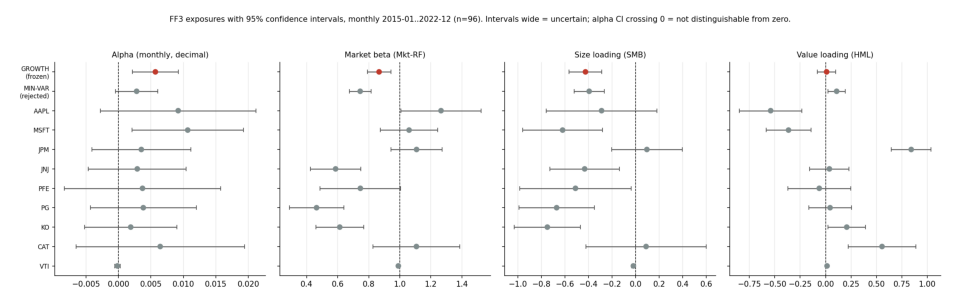

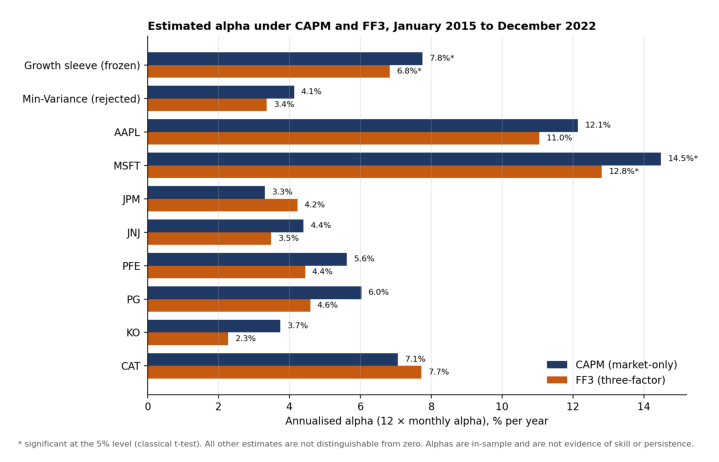

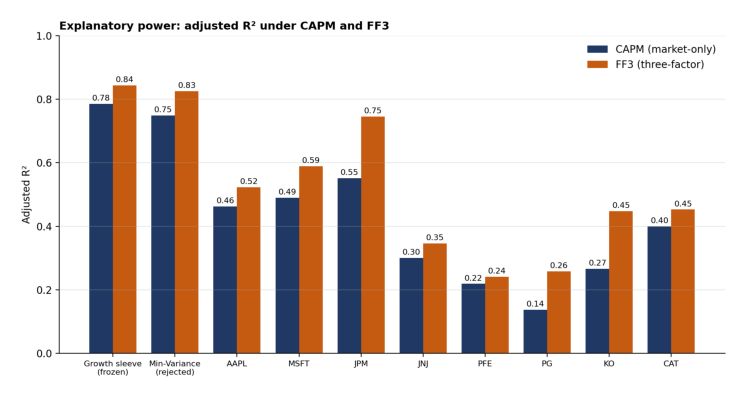

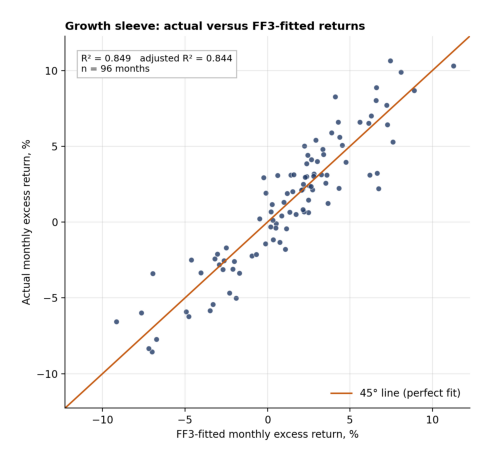

In [11]:
paths = [OUT / "factor_exposures.png"] + figures.make_figures(ROOT, coef, out_dir=OUT)
for p in paths:
    fig = plt.figure(figsize=(11, 5.6) if "exposures" in p.name else (8.5, 5.2))
    plt.imshow(plt.imread(p))
    plt.axis("off")
    plt.show()

## 7. Summary of findings (generated from the results above)

In [12]:
g_capm, g_ff3 = a, b
sig = coef[(coef.model == "FF3") & (coef.alpha_p < 0.05)].strategy_or_ticker.tolist()
print(f"1. Market exposure: the growth sleeve has a market loading of {g_ff3.Mkt_RF:.2f} (95% CI {g_ff3.Mkt_RF_ci95_lo:.2f} to {g_ff3.Mkt_RF_ci95_hi:.2f}); "
      f"adjusted R-squared rises from {g_capm.r2_adj:.3f} (CAPM) to {g_ff3.r2_adj:.3f} (FF3).")
print(f"2. Size and value: SMB loading {g_ff3.SMB:.2f} (t = {g_ff3.SMB_t:.2f}), HML loading {g_ff3.HML:.3f} (t = {g_ff3.HML_t:.2f}). "
      "A negative SMB loading indicates a large-capitalisation tilt.")
print(f"3. Alpha: {g_capm.alpha:.2%} per month under CAPM and {g_ff3.alpha:.2%} under FF3 (annualised {g_ff3.alpha * 12:.2%}); "
      f"p = {g_ff3.alpha_p:.4f} under FF3.")
print(f"4. Alpha significant at the 5% level under FF3 for {len(sig)} of {coef.strategy_or_ticker.nunique()} subjects: {sig}. "
      f"Bonferroni threshold for {coef.strategy_or_ticker.nunique()} tests: {0.05 / coef.strategy_or_ticker.nunique():.4f}.")
print(f"5. Attribution: market exposure explains {parts['Market (loading x mean Mkt-RF)'] / total:.0%} of the sample mean excess return, "
      f"size {parts['Size (loading x mean SMB)'] / total:.0%}, value {parts['Value (loading x mean HML)'] / total:.0%}, intercept {parts['Alpha (intercept)'] / total:.0%}.")

1. Market exposure: the growth sleeve has a market loading of 0.87 (95% CI 0.79 to 0.94); adjusted R-squared rises from 0.785 (CAPM) to 0.844 (FF3).
2. Size and value: SMB loading -0.43 (t = -6.10), HML loading 0.010 (t = 0.22). A negative SMB loading indicates a large-capitalisation tilt.
3. Alpha: 0.65% per month under CAPM and 0.57% under FF3 (annualised 6.83%); p = 0.0019 under FF3.
4. Alpha significant at the 5% level under FF3 for 2 of 11 subjects: ['GROWTH_FROZEN_SAMPLE_MV', 'MSFT']. Bonferroni threshold for 11 tests: 0.0045.
5. Attribution: market exposure explains 55% of the sample mean excess return, size 2%, value -0%, intercept 43%.


### Interpretation and limits

- **What the alpha does and does not establish.** As stated in Lecture 7, a significant positive alpha is evidence of outperformance relative to the chosen model; it does not establish skill by itself.
  The weights were optimised on the same 2015 to 2022 sample and the universe was identified retrospectively, so a positive in-sample alpha is partly mechanical. Persistence is not tested here.
- **Multiple testing.** Eleven subjects are tested under two models; the sleeve and its constituents are not independent, so the Bonferroni threshold is a conservative guide only.
- **Return construction.** The estimation series uses constant weights; the 2023 to 2025 evaluation uses buy-and-hold weights that drift.
- **Specification.** Only market, size and value factors are included. The Carhart (momentum) and five-factor models of Lecture 7 are not estimated.
- **Data vintage.** Yahoo and French series were retrieved in October 2026 and may include revisions made after 31 December 2022.

## 8. Provenance

In [13]:
rec = pd.read_json(ROOT / "factor_analysis/data/raw/french/french_source_record.json", typ="series")
print("French retrieval record:")
for k in ["download_url", "retrieved_utc", "http_status", "size_bytes", "sha256"]:
    print(f"  {k}: {rec.get(k)}")
print("Result tables: factor_analysis/outputs/ | Figures: factor_analysis/outputs/figures/ | Report: factor_analysis/docs/eta_theta_assessment.md")

French retrieval record:
  download_url: https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/F-F_Research_Data_Factors_CSV.zip
  retrieved_utc: 2026-10-19T21:10:23.315480+00:00
  http_status: 200
  size_bytes: 13065
  sha256: 593f4fbef03181bc0b22ff6292f217689dd1fb79355049ca905d95b262040a66
Result tables: factor_analysis/outputs/ | Figures: factor_analysis/outputs/figures/ | Report: factor_analysis/docs/eta_theta_assessment.md
